# Lab 2 — What Did the Campaign Deliver?
Name: Protoriev Igor | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

**Conventions used below** (they follow the "Rules for this lab"):
- persons = **R and L only**, S guests are excluded; weights belong to broadcast days (06:00 → 05:59);
- a person *saw a spot* if they were watching that network at the spot's `start_ts` (session start ≤ spot start < session end);
- spot impressions = sum of the **daily weights** of the people who saw it; spot rating = impressions ÷ sum of daily weights of everyone in-tab that broadcast day **in the same audience** × 100;
- GRPs = sum of the spots' ratings; reach and frequency distributions use one **monthly weight** per person (average of their daily weights over their in-tab days);
- average frequency = GRPs ÷ reach; a spot costs *rate-card price × length ÷ 30*; big networks = CBS, NBC, ABC, FOX, FNC, small = FX, BRAVO, HGTV, FOOD, HIST.

In [2]:
pd.options.display.float_format = "{:,.2f}".format

BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]
NETS = BIG + SMALL

for df in (programs, viewings, commercials):
    for col in ["start_ts", "end_ts"]:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col]).dt.tz_localize(None)
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"]).dt.normalize()
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).dt.normalize()

dw_p = daily_weights[daily_weights.resp_type.isin(["R", "L"])].copy()
pv = viewings[viewings.resp_type.isin(["R", "L"])]

age = viewer_attributes[viewer_attributes.attr_id == 300].drop_duplicates("respondent_id").set_index("respondent_id").value
women = viewer_attributes[viewer_attributes.attr_id == 202].respondent_id
dw_p["age"] = dw_p.respondent_id.map(age)
dw_p["target"] = dw_p.age.between(18, 49)
dw_p["w1834"] = dw_p.respondent_id.isin(women) & dw_p.age.between(18, 34)

persons = dw_p.drop_duplicates("respondent_id").set_index("respondent_id")[["target", "w1834"]]
persons["monthly"] = dw_p.groupby("respondent_id").weight.mean()
total_p2 = persons.monthly.sum()
total_t = persons.monthly[persons.target].sum()

den_p2 = dw_p.groupby("broadcast_date").weight.sum()
den_t = dw_p[dw_p.target].groupby("broadcast_date").weight.sum()
n_tab = dw_p.groupby("broadcast_date").respondent_id.nunique()

## Task 1.1 — Size

In [3]:
brand_a = commercials[commercials.brand == "BRAND_A"]
print("Spots:", commercials.ad_airing_id.nunique())
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())
print("BRAND_A spots:", len(brand_a))
brand_a_by_net = brand_a.groupby("network_code").size().reindex(NETS, fill_value=0).to_frame("BRAND_A spots")
brand_a_by_net["share of spots"] = brand_a_by_net["BRAND_A spots"] / len(brand_a)
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,BRAND_A spots,share of spots
network_code,,
CBS,22,0.07
NBC,16,0.05
ABC,29,0.10
FOX,13,0.04
FNC,40,0.13
FX,38,0.13
BRAVO,33,0.11
HGTV,39,0.13
FOOD,33,0.11


## Task 1.2 — Ad load

In [4]:
commercials["hour"] = commercials.start_ts.dt.floor("h")
seconds = commercials.groupby(["network_code", "hour"]).length_sec.sum()
hours_on_air = (programs.end_ts.max() - programs.start_ts.min()) / pd.Timedelta(hours=1)
ad_load = pd.DataFrame({
    "ad minutes per hour": (seconds / 60).groupby("network_code").mean(),
    "hours with ads": seconds.groupby("network_code").size()}).reindex(NETS)
ad_load["share of hours with ads"] = ad_load["hours with ads"] / hours_on_air
display(ad_load)
print("Heaviest ad load:", ad_load["ad minutes per hour"].idxmax())

with_type = commercials.merge(programs[["telecast_id", "program_type"]], on="telecast_id", how="left")
print("Spots inside local telecasts:", (with_type.program_type == "local").sum())
local_minutes = programs[programs.program_type == "local"].groupby("network_code").duration_min.sum()
local_share = (local_minutes / programs.groupby("network_code").duration_min.sum()).reindex(NETS).fillna(0)
display(local_share.to_frame("share of airtime that is local"))

,ad minutes per hour,hours with ads,share of hours with ads
network_code,,,
CBS,12.14,427,0.57
NBC,11.82,299,0.40
ABC,11.84,349,0.47
FOX,11.79,196,0.26
FNC,15.64,743,1.00
FX,12.92,621,0.83
BRAVO,13.43,623,0.84
HGTV,13.34,621,0.83
FOOD,13.11,620,0.83


Heaviest ad load: FNC
Spots inside local telecasts: 0


,share of airtime that is local
network_code,
CBS,0.49
NBC,0.65
ABC,0.59
FOX,0.75
FNC,0.00
FX,0.00
BRAVO,0.00
HGTV,0.00
FOOD,0.00


**Answer:** the broadcast networks hand some hours to their local stations (*Local / Syndicated Programming*), and the breaks in those hours are sold locally, not nationally. `commercials` contains only **national** spots, so these hours have no rows at all: there are no spots inside local telecasts, and local programming takes 49% of CBS airtime, 65% of NBC, 59% of ABC and 75% of FOX. As a result the broadcast networks carry national ads in only 26–57% of the hours (FOX 26%, NBC 40%, ABC 47%, CBS 57%), while the cable networks have no local hours and carry ads in 83–84% of the hours (FNC in practically every hour: 743 of 744).

The heaviest ad load is on **FNC: 15.6 ad minutes per hour**, followed by the cable entertainment networks (12.9–13.4 minutes); the broadcast networks are the lightest (11.8–12.1 minutes).

## Task 1.3 — Price everything

In [5]:
spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")

is_program_row = rate_card.program_name.notna() & (rate_card.program_name != "")
program_rows = (rate_card[is_program_row][["network_code", "program_name", "daypart", "cost_30s_usd"]]
                .drop_duplicates(["network_code", "program_name"])
                .rename(columns={"daypart": "daypart_prog", "cost_30s_usd": "price_prog"}))
spots = spots.merge(program_rows, on=["network_code", "program_name"], how="left")

time_rows = rate_card[~is_program_row].copy()
start = time_rows.start_time.str.split(":", expand=True).astype(int)
end = time_rows.end_time.str.split(":", expand=True).astype(int)
time_rows["t0"] = start[0] * 60 + start[1] - 360
time_rows["t1"] = end[0] * 60 + end[1] - 360
time_rows = time_rows.explode("weekdays")
time_rows["weekdays"] = time_rows.weekdays.astype(int)

shifted = spots.start_ts - pd.Timedelta(hours=6)
spots["weekday"] = shifted.dt.dayofweek
spots["minute"] = shifted.dt.hour * 60 + shifted.dt.minute + shifted.dt.second / 60
by_time = spots[["ad_airing_id", "network_code", "weekday", "minute"]].merge(
    time_rows[["network_code", "weekdays", "t0", "t1", "daypart", "cost_30s_usd"]],
    left_on=["network_code", "weekday"], right_on=["network_code", "weekdays"])
by_time = by_time[(by_time.minute >= by_time.t0) & (by_time.minute < by_time.t1)]
by_time = (by_time.drop_duplicates("ad_airing_id")[["ad_airing_id", "daypart", "cost_30s_usd"]]
           .rename(columns={"daypart": "daypart_time", "cost_30s_usd": "price_time"}))
spots = spots.merge(by_time, on="ad_airing_id", how="left")

spots["selling_daypart"] = spots.daypart_prog.fillna(spots.daypart_time)
spots["price"] = spots.price_prog.fillna(spots.price_time)
spots["cost"] = spots.price * spots.length_sec / 30

print("Spots without a price:", spots.cost.isna().sum())
value = spots.groupby("network_code").cost.sum() / 1e6
value_program = spots[spots.price_prog.notna()].groupby("network_code").cost.sum() / 1e6
value_table = pd.DataFrame({"rate-card value (USD M)": value, "share from program rows": value_program / value})
display(value_table.reindex(NETS).fillna(0))

Spots without a price: 0


,rate-card value (USD M),share from program rows
network_code,,
CBS,818.78,0.23
NBC,724.32,0.34
ABC,708.79,0.43
FOX,696.17,0.84
FNC,315.85,0.00
FX,42.51,0.00
BRAVO,25.31,0.00
HGTV,58.10,0.00
FOOD,42.15,0.00


## Task 2.1 — Delivery

In [6]:
ba = spots[spots.brand == "BRAND_A"].set_index("ad_airing_id")
ba["bdate"] = (ba.start_ts - pd.Timedelta(hours=6)).dt.normalize()

sessions = {net: group for net, group in pv.groupby("network_code")}
parts = []
for ad_id, spot in ba.iterrows():
    s = sessions[spot.network_code]
    s = s[(s.start_ts <= spot.start_ts) & (s.end_ts > spot.start_ts)]
    parts.append(pd.DataFrame({"ad_airing_id": ad_id, "respondent_id": s.respondent_id.unique()}))

exposures = pd.concat(parts, ignore_index=True)
exposures = exposures.merge(ba[["network_code", "bdate", "cost"]], left_on="ad_airing_id", right_index=True)
exposures = exposures.merge(
    dw_p[["respondent_id", "broadcast_date", "weight", "target", "w1834"]].rename(columns={"broadcast_date": "bdate"}),
    on=["respondent_id", "bdate"])
exposures["monthly"] = exposures.respondent_id.map(persons.monthly)
print("Exposure rows:", len(exposures))
display(exposures.head())

ba["imp_p2"] = exposures.groupby("ad_airing_id").weight.sum()
ba["imp_t"] = exposures[exposures.target].groupby("ad_airing_id").weight.sum()
ba[["imp_p2", "imp_t"]] = ba[["imp_p2", "imp_t"]].fillna(0)
ba["rating_p2"] = ba.imp_p2 / ba.bdate.map(den_p2) * 100
ba["rating_t"] = ba.imp_t / ba.bdate.map(den_t) * 100

total_imp_p2 = ba.imp_p2.sum()
total_imp_t = ba.imp_t.sum()
grp_p2 = ba.rating_p2.sum()
grp_t = ba.rating_t.sum()
reach_p2 = persons.monthly.loc[exposures.respondent_id.unique()].sum() / total_p2 * 100
reach_t = persons.monthly.loc[exposures[exposures.target].respondent_id.unique()].sum() / total_t * 100

print("P2+ impressions (M):", round(total_imp_p2 / 1e6, 1))
print("P2+ GRPs:", round(grp_p2, 1))
print("P2+ reach (%):", round(reach_p2, 1))
print("P2+ average frequency:", round(grp_p2 / reach_p2, 2))
print("A18-49 impressions (M):", round(total_imp_t / 1e6, 1))
print("A18-49 GRPs:", round(grp_t, 1))
print("A18-49 reach (%):", round(reach_t, 1))
print("A18-49 average frequency:", round(grp_t / reach_t, 2))

Exposure rows: 11289


,ad_airing_id,respondent_id,network_code,bdate,cost,weight,target,w1834,monthly
0,70032399,10259601,BRAVO,2024-10-06,870.00,26259,True,False,"26,265.14"
1,70032399,10359202,BRAVO,2024-10-06,870.00,26259,True,False,"26,243.97"
2,70032399,10143501,BRAVO,2024-10-06,870.00,24787,False,False,"24,742.48"
3,70032647,10230303,BRAVO,2024-10-07,580.00,40453,False,False,"40,215.48"
4,70032744,10185402,HIST,2024-10-07,940.00,43336,False,False,"43,843.06"


P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

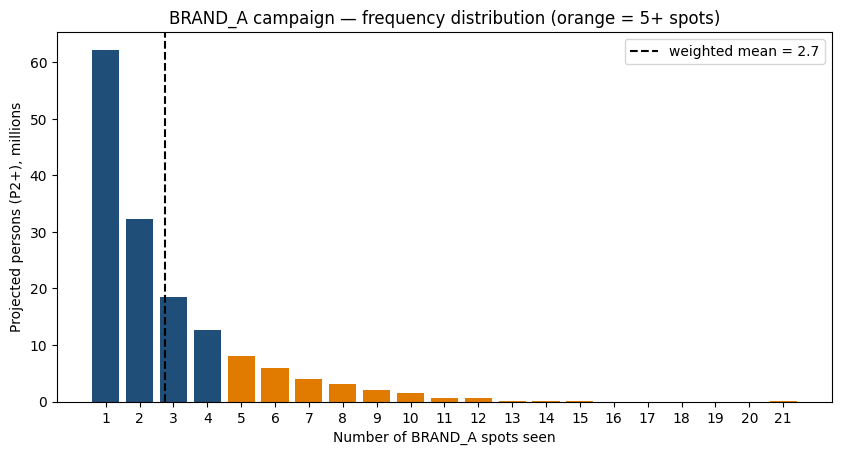

Share of impressions at 5+ exposures: 0.444
Persons reached (M): 152.3
Weighted mean frequency: 2.75
Weighted median frequency: 2
Share of reached persons who saw only 1 spot: 0.409
Share of reached persons with 5+ spots: 0.175


In [7]:
people = pd.DataFrame({"freq": exposures.groupby("respondent_id").size()})
people["monthly"] = persons.monthly
dist = people.groupby("freq").monthly.sum() / 1e6
dist = dist.reindex(range(1, people.freq.max() + 1), fill_value=0)
mean_freq = (people.freq * people.monthly).sum() / people.monthly.sum()

colors = ["#e07b00" if f >= 5 else "#1f4e79" for f in dist.index]
plt.figure(figsize=(10, 4.8))
plt.bar(dist.index, dist.values, color=colors)
plt.axvline(mean_freq, color="black", linestyle="--", label=f"weighted mean = {mean_freq:.1f}")
plt.xticks(dist.index)
plt.xlabel("Number of BRAND_A spots seen")
plt.ylabel("Projected persons (P2+), millions")
plt.title("BRAND_A campaign — frequency distribution (orange = 5+ spots)")
plt.legend()
plt.show()

exposures["freq"] = exposures.respondent_id.map(people.freq)
print("Share of impressions at 5+ exposures:", round(exposures.weight[exposures.freq >= 5].sum() / exposures.weight.sum(), 3))

people = people.sort_values("freq")
cum_share = people.monthly.cumsum() / people.monthly.sum()
print("Persons reached (M):", round(people.monthly.sum() / 1e6, 1))
print("Weighted mean frequency:", round(mean_freq, 2))
print("Weighted median frequency:", people.freq[cum_share >= 0.5].iloc[0])
print("Share of reached persons who saw only 1 spot:", round(people.monthly[people.freq == 1].sum() / people.monthly.sum(), 3))
print("Share of reached persons with 5+ spots:", round(people.monthly[people.freq >= 5].sum() / people.monthly.sum(), 3))

**Answer:** no, the average frequency is not a fair summary. The distribution is strongly right-skewed: the most frequent value is 1 (about 62 million people, 40.9% of the 152.3 million persons reached), the bars fall quickly and the tail goes up to 21 spots. The weighted mean of 2.75 is above the median of 2 and describes hardly anyone: it lies between the many people who saw the brand once and the few who saw it very often.

The 17.5% of reached persons who saw 5 or more spots received **44.4%** of all impressions, so almost half of the impressions went to a small group that was already heavily exposed, while 40.9% of the reached people saw the brand only once. The full distribution (or the median and the share at 5+) shows this; "an average frequency of 3" does not.

## Task 2.3 — On target?

In [8]:
pop_share = total_t / total_p2
print("Share of impressions on A18-49:", round(total_imp_t / total_imp_p2, 3))
print("A18-49 share of all persons:", round(pop_share, 3))

by_net = ba.groupby("network_code")[["imp_p2", "imp_t"]].sum().reindex(NETS)
target_table = pd.DataFrame({
    "P2+ imp (M)": by_net.imp_p2 / 1e6,
    "A18-49 imp (M)": by_net.imp_t / 1e6,
    "share on target": by_net.imp_t / by_net.imp_p2})
target_table["index vs population"] = target_table["share on target"] / pop_share * 100
target_table["contribution (pp)"] = (by_net.imp_t - pop_share * by_net.imp_p2) / total_imp_p2 * 100
display(target_table)
print("Sum of contributions (pp) = share on target minus population share:", round(target_table["contribution (pp)"].sum(), 1))

Share of impressions on A18-49: 0.194
A18-49 share of all persons: 0.422


,P2+ imp (M),A18-49 imp (M),share on target,index vs population,contribution (pp)
network_code,,,,,
CBS,88.98,13.69,0.15,36.49,-5.69
NBC,41.44,7.83,0.19,44.83,-2.30
ABC,94.21,16.99,0.18,42.76,-5.43
FOX,76.26,18.44,0.24,57.35,-3.28
FNC,57.80,2.72,0.05,11.15,-5.17
FX,8.52,5.55,0.65,154.46,0.47
BRAVO,5.08,2.82,0.55,131.41,0.16
HGTV,24.66,7.55,0.31,72.66,-0.68
FOOD,9.48,2.99,0.32,74.83,-0.24


Sum of contributions (pp) = share on target minus population share: -22.8


**Answer:** the campaign **under-delivered** against its target. Only 19.4% of the impressions landed on adults 18–49, while this group is 42.2% of all persons: a gap of 22.8 percentage points (a target index of 46).

The big networks explain it: they gave 86% of all P2+ impressions, and their audiences are old. Only 5% of the FNC impressions fell on the target (index 11), 15% on CBS (index 36), 18% on ABC (43), 19% on NBC (45) and 24% on FOX (57). The most negative contributions are CBS (−5.7 pp), ABC (−5.4 pp) and FNC (−5.2 pp), then FOX (−3.3 pp) and NBC (−2.3 pp). Only FX (index 154) and BRAVO (index 131) over-delivered, but with 8.5 and 5.1 million P2+ impressions they are too small to compensate (+0.5 and +0.2 pp).

## Task 3.1 — Cost

In [9]:
cost_total = ba.cost.sum()
print("Campaign cost (USD):", round(cost_total))
print("P2+ CPM (USD):", round(cost_total / total_imp_p2 * 1000, 2))
print("P2+ CPP (USD):", round(cost_total / grp_p2))
print("A18-49 CPM (USD):", round(cost_total / total_imp_t * 1000, 2))
print("A18-49 CPP (USD):", round(cost_total / grp_t))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [10]:
by_net = ba.groupby("network_code")
net_table = pd.DataFrame({
    "spots": by_net.size(),
    "cost (USD)": by_net.cost.sum(),
    "P2+ imp (M)": by_net.imp_p2.sum() / 1e6,
    "A18-49 imp (M)": by_net.imp_t.sum() / 1e6}).reindex(NETS)
net_table["share of cost"] = net_table["cost (USD)"] / net_table["cost (USD)"].sum()
net_table["P2+ CPM"] = net_table["cost (USD)"] / (net_table["P2+ imp (M)"] * 1e6) * 1000
net_table["A18-49 CPM"] = net_table["cost (USD)"] / (net_table["A18-49 imp (M)"] * 1e6) * 1000
display(net_table)
print("Cheapest networks for A18-49 (CPM):", net_table["A18-49 CPM"].nsmallest(3).round(2).to_dict())
print("Most expensive networks for A18-49 (CPM):", net_table["A18-49 CPM"].nlargest(3).round(2).to_dict())
print("Share of cost on big networks:", round(net_table.loc[BIG, "cost (USD)"].sum() / net_table["cost (USD)"].sum(), 3))

,spots,cost (USD),P2+ imp (M),A18-49 imp (M),share of cost,P2+ CPM,A18-49 CPM
network_code,,,,,,,
CBS,22,"1,488,700.00",88.98,13.69,0.20,16.73,108.72
NBC,16,"796,800.00",41.44,7.83,0.11,19.23,101.72
ABC,29,"1,625,700.00",94.21,16.99,0.22,17.26,95.69
FOX,13,"2,434,700.00",76.26,18.44,0.33,31.93,132.03
FNC,40,"526,300.00",57.80,2.72,0.07,9.11,193.70
FX,38,"92,200.00",8.52,5.55,0.01,10.82,16.61
BRAVO,33,"49,610.00",5.08,2.82,0.01,9.76,17.61
HGTV,39,"230,000.00",24.66,7.55,0.03,9.33,30.45
FOOD,33,"96,620.00",9.48,2.99,0.01,10.19,32.29


Cheapest networks for A18-49 (CPM): {'FX': 16.61, 'BRAVO': 17.61, 'HGTV': 30.45}
Most expensive networks for A18-49 (CPM): {'FNC': 193.7, 'FOX': 132.03, 'CBS': 108.72}
Share of cost on big networks: 0.926


**Answer:** the money went to the big networks: they took 92.6% of the budget ($6.87M of $7.42M). FOX alone took 33% with only 13 spots (about $187,000 per spot), then ABC 22%, CBS 20%, NBC 11% and FNC 7%; the five small networks together got only 7.4%.

Per target impression the picture is reversed. The cheapest networks for A18–49 are FX ($16.61 CPM), BRAVO ($17.61) and HGTV ($30.45); FOOD and HIST are about $32. The most expensive are FNC ($193.70), FOX ($132.03) and CBS ($108.72). Every small network is cheaper than every big one (the cheapest big network, ABC, costs $95.69), roughly 3 to 12 times. FNC has the lowest P2+ CPM among the big networks ($9.11), but it is the most expensive way to reach the target because its audience is old; the campaign's overall A18–49 CPM ($91.53) is more than five times its P2+ CPM ($17.72).

## Task 3.3 — Guarantee

In [11]:
met = grp_p2 >= 150
owed = max(0, 150 - grp_p2)
print("Guarantee met:", met)
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cost_total / grp_p2))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [12]:
saw_big = exposures[exposures.network_code.isin(BIG)].respondent_id.drop_duplicates()
saw_small = exposures[exposures.network_code.isin(SMALL)].respondent_id.drop_duplicates()
saw_both = saw_big[saw_big.isin(saw_small)]
saw_all = exposures.respondent_id.drop_duplicates()

r_big = persons.monthly.loc[saw_big].sum() / total_p2 * 100
r_small = persons.monthly.loc[saw_small].sum() / total_p2 * 100
r_both = persons.monthly.loc[saw_both].sum() / total_p2 * 100
r_all = persons.monthly.loc[saw_all].sum() / total_p2 * 100
r_independent = r_big * r_small / 100
added = r_all - r_big
cost_big = ba.cost[ba.network_code.isin(BIG)].sum()
cost_small = ba.cost[ba.network_code.isin(SMALL)].sum()

print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(r_both, 1))
print("Overlap if independent (%):", round(r_independent, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", round(cost_small / added))
print("Cost per reach point, big (USD):", round(cost_big / r_big))

print("Check: big + small - overlap = whole campaign:", abs(r_big + r_small - r_both - r_all) < 0.000001)
print("Share of the small networks' reach also reached by the big ones (%):", round(r_both / r_small * 100, 1))
print("Cost of big / small networks (USD):", round(cost_big), "/", round(cost_small))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456
Check: big + small - overlap = whole campaign: True
Share of the small networks' reach also reached by the big ones (%): 70.2
Cost of big / small networks (USD): 6872200 / 548070


**Answer:** reach counts **people**, not impressions, and the same person can be reached by several networks, so the groups' reaches cannot be added: the big networks reach 39.8% of P2+ and the small ones 12.4%, but the whole campaign reaches only 43.5%, not 52.2%, because 8.7 points of P2+ were reached by both groups (*whole = big + small − overlap*, checked above).

The overlap of 8.7% is almost twice what independent audiences would give (4.9%). Of the people reached by the small networks, 70.2% were also reached by the big ones, against 39.8% of all persons, so the small networks' viewers are **more** likely than average to have been reached by the big networks too. The reason is that TV viewing is not random: heavy viewers watch many networks and are reached again and again, while light viewers are rarely reached by any of them, so the small networks mostly re-reach people the big networks already had.

Was the small-network money well spent? They added only 3.7 points of reach, but each added point cost $148,706 against $172,456 per reach point on the big networks, about 14% cheaper, and the small networks cost only 7.4% of the budget ($548,070). So in cost per point they were a reasonable buy, even though their added reach is small; and, as Task 3.2 showed, they are by far the cheapest way to reach the target.

## Task 5 — How sure are we?

In [13]:
ba["panelists"] = exposures.groupby("ad_airing_id").size()
ba["panelists_w1834"] = exposures[exposures.w1834].groupby("ad_airing_id").size()
ba[["panelists", "panelists_w1834"]] = ba[["panelists", "panelists_w1834"]].fillna(0)
ba["big"] = ba.network_code.isin(BIG)
ba["no_panelist"] = ba.panelists == 0

p = ba.rating_p2 / 100
ba["se"] = (p * (1 - p) / ba.bdate.map(n_tab)) ** 0.5 * 100
ba["relative_se"] = (ba.se / ba.rating_p2).where(ba.rating_p2 > 0)

table5 = ba.groupby("network_code").agg(
    spots=("panelists", "size"),
    median_panelists=("panelists", "median"),
    spots_seen_by_no_panelist=("no_panelist", "sum"),
    median_p2_rating=("rating_p2", "median"),
    median_relative_se=("relative_se", "median")).reindex(NETS)
display(table5)

print("Spots seen by no panelist:", ba.no_panelist.sum())
print("Median relative SE, big networks:", round(ba.relative_se[ba.big].median(), 3))
print("Median relative SE, small networks:", round(ba.relative_se[~ba.big].median(), 3))
print("W18-34 zero-cell spots:", (ba.panelists_w1834 == 0).sum())

print("P2+ rating of the spots seen by no panelist:", ba.rating_p2[ba.no_panelist].unique())
print("Zero-panelist spots on small networks:", ba.no_panelist[~ba.big].sum(), "of", (~ba.big).sum())
print("Median panelists per spot, big / small:", ba.panelists[ba.big].median(), "/", ba.panelists[~ba.big].median())
print("Spots with fewer than 5 W18-34 panelists:", (ba.panelists_w1834 < 5).sum())

,spots,median_panelists,spots_seen_by_no_panelist,median_p2_rating,median_relative_se
network_code,,,,,
CBS,22,69.00,0,0.84,0.11
NBC,16,68.50,0,0.81,0.12
ABC,29,57.00,0,0.71,0.12
FOX,13,145.00,0,1.64,0.08
FNC,40,31.00,0,0.40,0.16
FX,38,5.50,4,0.05,0.42
BRAVO,33,3.00,3,0.03,0.54
HGTV,39,11.00,0,0.12,0.30
FOOD,33,5.00,2,0.06,0.42


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171
P2+ rating of the spots seen by no panelist: [0.]
Zero-panelist spots on small networks: 10 of 180
Median panelists per spot, big / small: 57.5 / 5.0
Spots with fewer than 5 W18-34 panelists: 273


**Answer:** a zero rating does **not** mean that nobody saw the spot. It means that none of the panelists happened to be watching, so the panel cannot resolve audiences below roughly one panelist's weight; the true rating is small but not zero. Here 10 of the 300 spots were seen by no panelist and get a rating of 0.0, and **all of them ran on small networks** (FX 4, BRAVO 3, FOOD 2, HIST 1; 10 of the 180 small-network spots).

This is what a panel does to small networks. The median spot on a big network was seen by 57.5 panelists, on a small network by only 5 (BRAVO just 3), so the median relative standard error is 0.122 for the big networks (about 12% of the rating) and 0.417 for the small ones (about 42%), more than three times larger. The formula assumes a simple random sample; a weighted panel behaves like a smaller one, so the real errors are larger and these numbers are a lower bound.

What I would tell the client: do not report the W18–34 rating **by spot**. In 171 of the 300 spots (57%) not a single woman aged 18–34 in the panel saw the spot (a zero-cell), and 273 spots have fewer than 5 such panelists, so the rating of one spot rests on a few people or none and is mostly noise. Report W18–34 for the whole campaign, or by groups of spots (network type, daypart), where enough panelists stand behind the number, and for single spots show only the P2+ or A18–49 rating together with its margin of error.